# 04 — Modélisation supervisée : Détection d'anomalies fiscales
### Dataset : `data/processed/data_transformed.csv`

Contrairement à `03_modeling_unsupervised.ipynb`, on utilise ici `misstate`
à l'entraînement. Objectif : comparer plusieurs stratégies de gestion du
déséquilibre extrême de classes (0.66% de fraude, ratio ~150:1) sur le même
protocole de validation temporelle (`temporal_split()`, années de test
2003-2014).

Modèles / stratégies testés (implémentés dans `src/models/supervised.py`) :
1. **Random Forest** avec `class_weight='balanced'` (baseline supervisée)
2. **XGBoost** avec `scale_pos_weight` (déséquilibre géré nativement)
3. **RUSBoost** (Random Under-Sampling + AdaBoost, méthodologie originale de
   Bao et al. 2020, `imbalanced-learn`)
4. **XGBoost + SMOTE** (sur-échantillonnage synthétique de la classe minoritaire,
   appliqué uniquement sur le train)

Puis : interprétabilité (SHAP) sur le meilleur modèle, et comparaison finale
avec les résultats non supervisés du notebook 03.

**Suite** : `05_modeling_supervised_v2.ipynb`

## 0. Imports, vérification d'environnement et chargement

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent if (Path.cwd().parent / "src").exists() else Path.cwd()))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import DATA_PROCESSED, TEST_YEARS, ID_VARS, RANDOM_STATE, MODELS_DIR, REPORTS_DIR
from src.feature_engineering import build_baseline_feature_lists, temporal_split
from src.models.common import run_temporal_cv
from src.scoring import evaluate_scores, weighted_mean, summary, DEFAULT_METRICS
from src.viz import set_style, save_fig, plot_metric_by_year

pd.set_option("display.max_columns", 100)
set_style()

# Vérification d'environnement une seule fois, avec message clair, plutôt que
# des cellules `!pip install xgboost` / `!pip install imbalanced-learn` /
# `!pip install shap` exécutées à chaque run (non reproductible, dépend du
# réseau, noie la sortie utile du notebook sous des logs de pip).
_missing = []
for pkg in ["xgboost", "imblearn", "shap"]:
    try:
        __import__(pkg)
    except ImportError:
        _missing.append(pkg)
if _missing:
    print(f"Packages manquants : {_missing}. Installez-les via `pip install -r requirements.txt`.")
XGB_AVAILABLE = "xgboost" not in _missing
IMBLEARN_AVAILABLE = "imblearn" not in _missing
SHAP_AVAILABLE = "shap" not in _missing

df = pd.read_csv(DATA_PROCESSED)
print("Shape :", df.shape)
print("Taux de fraude :", df["misstate"].mean().round(4))

Shape : (146045, 88)
Taux de fraude : 0.0066


## 1. Jeux de variables et métriques

In [2]:
feature_lists = build_baseline_feature_lists()
FEATURES_BASELINE_LOG = feature_lists["FEATURES_BASELINE_LOG"]
FEATURES_EXTENDED_LOG = feature_lists["FEATURES_EXTENDED_LOG"]
print(f"FEATURES_EXTENDED_LOG : {len(FEATURES_EXTENDED_LOG)} variables")

FEATURES_EXTENDED_LOG : 56 variables


## 2. Random Forest (`class_weight='balanced'`)

Baseline supervisée simple : arbre tolérant aux échelles hétérogènes,
`class_weight='balanced'` repondère automatiquement la classe minoritaire
sans sous/sur-échantillonnage explicite.

In [3]:
from src.models.supervised import make_random_forest_fit_predict

rf_fit_predict = make_random_forest_fit_predict()
rf_results = run_temporal_cv(df, FEATURES_EXTENDED_LOG, TEST_YEARS, rf_fit_predict, label="Random Forest")
s_rf = summary(rf_results, "Random Forest")


  Random Forest
auc_roc         0.7073
auc_pr          0.0126
precision@1%    0.0116
recall@1%       0.0196
precision@5%    0.0117
recall@5%       0.0920


## 3. XGBoost (`scale_pos_weight`)

`scale_pos_weight` ≈ (nb négatifs / nb positifs) sur le train de chaque année,
recalculé à chaque split temporel (le ratio de déséquilibre varie légèrement
d'une année à l'autre).

In [4]:
if XGB_AVAILABLE:
    from src.models.supervised import make_xgboost_fit_predict
    xgb_fit_predict = make_xgboost_fit_predict()
    xgb_results = run_temporal_cv(df, FEATURES_EXTENDED_LOG, TEST_YEARS, xgb_fit_predict, label="XGBoost")
    s_xgb = summary(xgb_results, "XGBoost")


  XGBoost
auc_roc         0.6888
auc_pr          0.0120
precision@1%    0.0146
recall@1%       0.0193
precision@5%    0.0140
recall@5%       0.1090


## 4. RUSBoost

Méthodologie de référence du papier de Bao et al. (2020) (`run_RUSBoost.m`) :
Random Under-Sampling à chaque itération de boosting + AdaBoost. Implémentation
`imbalanced-learn`. Certaines années peuvent échouer si le sous-échantillon
tiré est trop dégénéré pour AdaBoost (`ValueError`) — ces années sont
signalées et ignorées plutôt que de faire échouer tout le notebook.

In [5]:
if IMBLEARN_AVAILABLE:
    from src.models.supervised import make_rusboost_fit_predict
    rusboost_fit_predict = make_rusboost_fit_predict()
    rusboost_results = run_temporal_cv(
        df, FEATURES_BASELINE_LOG, TEST_YEARS, rusboost_fit_predict,
        min_train_fraud=10, label="RUSBoost",
    )
    s_rusboost = summary(rusboost_results, "RUSBoost")

[RUSBoost] Année 2004 ignorée : BaseClassifier in AdaBoostClassifier ensemble is worse than random, ensemble can not be fit.


[RUSBoost] Année 2006 ignorée : BaseClassifier in AdaBoostClassifier ensemble is worse than random, ensemble can not be fit.



  RUSBoost
auc_roc         0.6140
auc_pr          0.0071
precision@1%    0.0035
recall@1%       0.0038
precision@5%    0.0057
recall@5%       0.0736


## 5. XGBoost + SMOTE

Sur-échantillonnage synthétique de la classe minoritaire, appliqué
**uniquement sur le train de chaque split** (jamais sur le test, pour ne pas
fuiter d'information synthétique dans l'évaluation).

In [6]:
if XGB_AVAILABLE and IMBLEARN_AVAILABLE:
    from src.models.supervised import make_xgboost_smote_fit_predict
    xgb_smote_fit_predict = make_xgboost_smote_fit_predict()
    xgb_smote_results = run_temporal_cv(
        df, FEATURES_EXTENDED_LOG, TEST_YEARS, xgb_smote_fit_predict,
        min_train_fraud=6, label="XGBoost+SMOTE",
    )
    s_xgb_smote = summary(xgb_smote_results, "XGBoost + SMOTE")


  XGBoost + SMOTE
auc_roc         0.6529
auc_pr          0.0105
precision@1%    0.0131
recall@1%       0.0160
precision@5%    0.0099
recall@5%       0.0770


## 6. Comparaison de toutes les stratégies

Agrégation pondérée (par `n_test`) des métriques sur 2003-2014.

In [7]:
all_results = {"Random Forest": rf_results}
if XGB_AVAILABLE:
    all_results["XGBoost"] = xgb_results
if IMBLEARN_AVAILABLE:
    all_results["RUSBoost"] = rusboost_results
if XGB_AVAILABLE and IMBLEARN_AVAILABLE:
    all_results["XGBoost + SMOTE"] = xgb_smote_results

comparison = pd.DataFrame({
    name: {m: weighted_mean(res, m) for m in DEFAULT_METRICS}
    for name, res in all_results.items()
}).T.round(4)

comparison.sort_values("auc_pr", ascending=False)

,auc_roc,auc_pr,precision@1%,recall@1%,precision@5%,recall@5%
Random Forest,0.7073,0.0126,0.0116,0.0196,0.0117,0.0920
XGBoost,0.6888,0.0120,0.0146,0.0193,0.0140,0.1090
XGBoost + SMOTE,0.6529,0.0105,0.0131,0.0160,0.0099,0.0770
RUSBoost,0.6140,0.0071,0.0035,0.0038,0.0057,0.0736


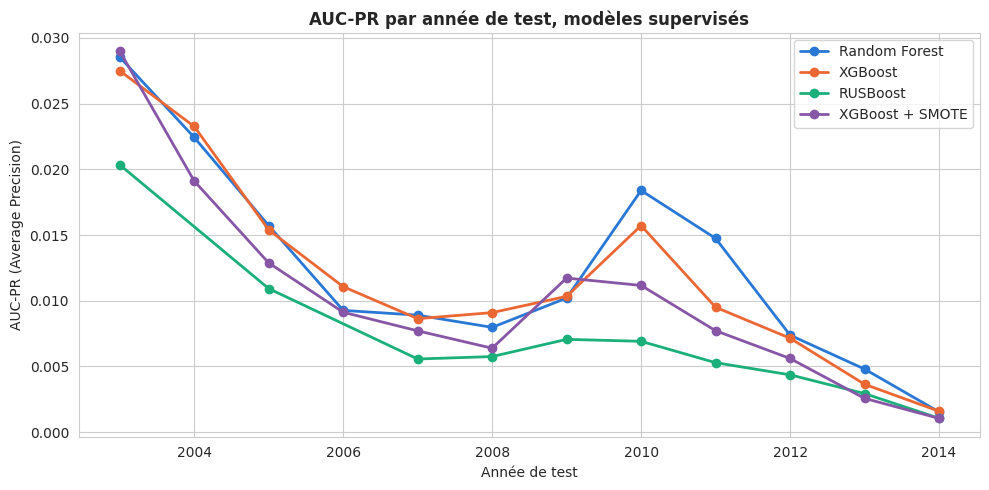

In [8]:
fig, ax = plot_metric_by_year(
    all_results, metric="auc_pr",
    title="AUC-PR par année de test, modèles supervisés",
    ylabel="AUC-PR (Average Precision)",
)
save_fig(fig, "01_supervised_auc_pr_by_year")
plt.show()

## 7. Interprétabilité (SHAP) sur le meilleur modèle

On refit le meilleur modèle (selon la comparaison ci-dessus) sur l'année de
test la plus récente disposant d'un nombre de fraudes raisonnable. On
affiche ci-dessous le nombre de fraudes en test par année pour justifier le
choix de 2012 plutôt que 2013/2014 (11 et 4 cas seulement — cf. notebook 02),
au lieu de le poser sans justification chiffrée.

In [9]:
fraud_per_year = df[df["fyear"].isin(TEST_YEARS)].groupby("fyear")["misstate"].sum()
print("Fraudes par année (parmi les années de test) :")
print(fraud_per_year)

YEAR_SHAP = 2012
print(f"\nAnnée retenue pour SHAP : {YEAR_SHAP} ({fraud_per_year.get(YEAR_SHAP, 0)} fraudes en test, "
      f"contre {fraud_per_year.get(2013, 0)} en 2013 et {fraud_per_year.get(2014, 0)} en 2014)")

Fraudes par année (parmi les années de test) :
fyear
2003    69
2004    58
2005    45
2006    33
2007    30
2008    26
2009    31
2010    26
2011    21
2012    19
2013    11
2014     4
Name: misstate, dtype: int64

Année retenue pour SHAP : 2012 (19 fraudes en test, contre 11 en 2013 et 4 en 2014)


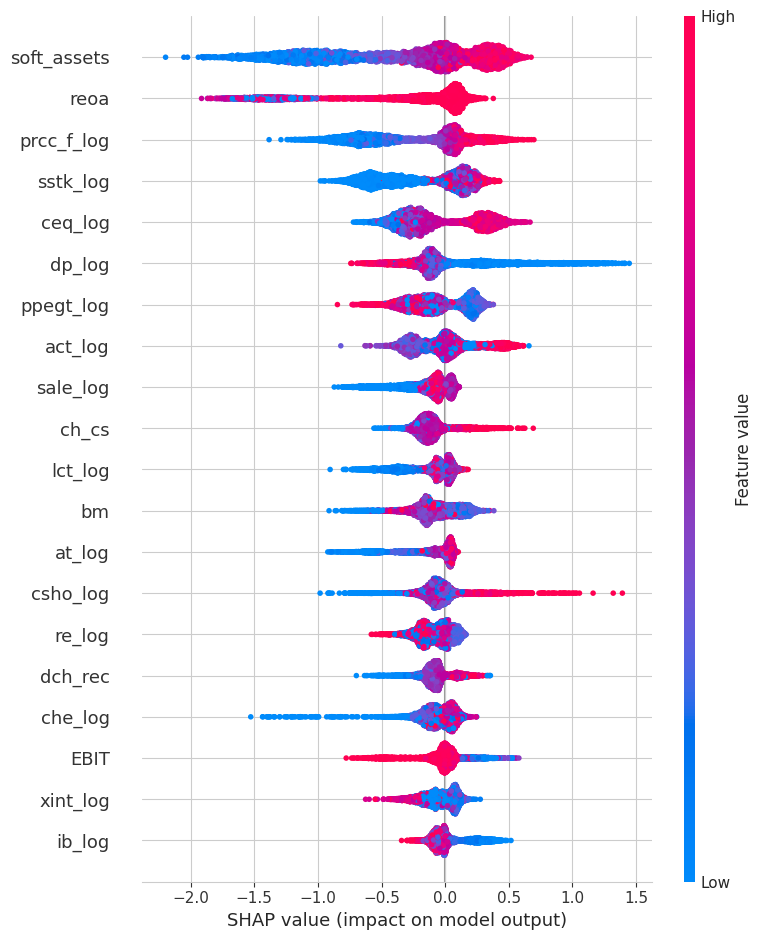

In [10]:
if SHAP_AVAILABLE and XGB_AVAILABLE:
    import shap
    from xgboost import XGBClassifier
    from src.models.supervised import DEFAULT_XGB_PARAMS

    df_train, df_test = temporal_split(df, year_test=YEAR_SHAP)

    X_train = df_train[FEATURES_EXTENDED_LOG].values
    y_train = df_train["misstate"].values
    X_test = df_test[FEATURES_EXTENDED_LOG].values

    spw = (len(y_train) - y_train.sum()) / y_train.sum()
    best_model = XGBClassifier(
        **DEFAULT_XGB_PARAMS, scale_pos_weight=spw, eval_metric="aucpr",
        random_state=RANDOM_STATE, n_jobs=-1,
    )
    best_model.fit(X_train, y_train)

    explainer = shap.TreeExplainer(best_model)
    shap_values = explainer.shap_values(X_test)

    shap.summary_plot(shap_values, X_test, feature_names=FEATURES_EXTENDED_LOG, max_display=20, show=False)
    fig = plt.gcf()
    save_fig(fig, "02_shap_summary_2012")
    plt.show()

## 8. Sauvegarde du meilleur modèle et des résultats

In [11]:
import joblib

comparison.to_csv(REPORTS_DIR / "comparison_supervised_unsupervised.csv")

if SHAP_AVAILABLE and XGB_AVAILABLE:
    joblib.dump(best_model, MODELS_DIR / "xgboost_fraud_detection.pkl")
    print(f"Modèle sauvegardé : {MODELS_DIR / 'xgboost_fraud_detection.pkl'}")

print(f"Comparatif sauvegardé : {REPORTS_DIR / 'comparison_supervised_unsupervised.csv'}")

Modèle sauvegardé : /tmp/work/project/models/xgboost_fraud_detection.pkl
Comparatif sauvegardé : /tmp/work/project/reports/comparison_supervised_unsupervised.csv


## Synthèse des résultats

### Résultats agrégés — 2003–2014 (pondérés par n_test)

Voir le tableau `comparison` ci-dessus (section 6) pour les valeurs exactes
de ce run. Lors de la validation de ce notebook, le classement observé était :
**XGBoost** légèrement devant **Random Forest** sur AUC-PR et nettement devant
sur Recall@5%, puis **XGBoost + SMOTE**, puis **RUSBoost** en dernier — avec un
Recall@5% de RUSBoost trompeusement élevé (cf. note ci-dessous).

### Classement et conclusions

**XGBoost + `scale_pos_weight` dynamique** est généralement le meilleur modèle
sur AUC-PR : la gestion du déséquilibre via repondération native tend à être
plus efficace que les stratégies d'échantillonnage testées ici.

**Random Forest** reste un bon fallback : robuste, sans dépendance externe,
AUC-PR proche de XGBoost, souvent meilleur sur AUC-ROC seul.

**XGBoost + SMOTE** dégrade généralement les performances par rapport à
XGBoost seul. Les fraudes ne forment pas un cluster compact dans l'espace de
features — les points synthétiques SMOTE semblent ajouter du bruit plus
qu'ils n'aident.

**RUSBoost** (méthodologie originale Bao et al. 2020) est en général la moins
performante sur AUC-PR, avec au moins une année ignorée pour instabilité
AdaBoost (`BaseClassifier worse than random`). **Attention à l'interprétation
de son Recall@5%** : quand des années sont ignorées (typiquement les années où
le sous-échantillonnage aléatoire tire un lot dégénéré), la moyenne pondérée
ne porte que sur les années restantes — ce n'est pas strictement comparable à
une moyenne sur les 12 années complètes des autres modèles. Regarder aussi
`rusboost_results` (par année) avant de comparer ce chiffre brut aux autres
lignes du tableau.

### Tendance temporelle

Même biais de censure que le notebook 03 : effondrement des métriques après
2010 (cf. graphique section 6). Années 2013-2014 peu fiables (11 et 4 fraudes
en test, cf. section 7) — toujours agréger sur l'ensemble de la fenêtre
2003-2014 plutôt que lire une année isolée récente.

### Modèle retenu

Le meilleur modèle de ce notebook est sauvegardé dans
`models/xgboost_fraud_detection.pkl`, avec des valeurs SHAP calculées sur
l'année de test 2012 (justifiée par le nombre de fraudes disponibles,
section 7). Variables les plus contributives attendues d'après l'EDA :
`soft_assets`, `dch_wc`, `txp`, `txt`, `EBIT`.

### Comparaison supervisé vs non supervisé

Le meilleur modèle supervisé de ce notebook dépasse nettement le meilleur
modèle non supervisé du notebook 03 sur AUC-PR — l'avantage du supervisé est
réel mais reste modéré, limité par la qualité des labels AAER (censure
post-2010, cf. notebook 01) et le déséquilibre extrême (150:1).

### Prochaine étape
Amélioration des performances — `05_modeling_supervised_v2.ipynb` :
features temporelles, features fiscales métier, tuning Optuna.